# Test run of both strategies with gemma4:31b on Ollama Cloud

A cheap end-to-end check of the pipeline on the 36 published DOLAP 2026 tasks, **one run per configuration**
(the experiment uses 5 and votes):

| | Strategy A (LLM only) | Strategy B (single-turn search agent) |
|---|---|---|
| Model | `gemma4:31b` (31B dense, BF16) on Ollama Cloud, free tier | same |
| Configurations | 9 published prompts × with / without graph context | `search_evidence` (answer only from search results), `search_memory` (search results + own knowledge), no graph context |
| Runs | 36 tasks × 18 variants × 1 run = 648 | 36 tasks × 2 variants × 1 run = 72 |
| Search | — | Tavily **basic** depth (1 credit per query), dataset sources blocked, credit cap 150 |
| Config | `configs/strategy_a_dolap2026.yaml` (`--runs 1`) | `configs/strategy_b_dolap2026_smoke.yaml` |

With one run there is no vote, so every number here carries the full sampling noise of a single answer at
temperature 0.7. The goal is to check that the code is right and the numbers are plausible, not to draw conclusions.

**Scoring** (as in `dolap2026_ollama.ipynb`):
- *Standard*: each hidden property H with a ground truth is **correct**, **wrong** or **abstained**.
  Precision = correct / answered, recall = correct / |H|, F1 from both.
- *Published*: the paper's tolerance rules over every answered property with a ground truth; precision is 1 by
  construction, so F1 = 2·acc / (1 + acc). Shown for Strategy A only, to place gemma4 next to Table 3.

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
from evaluation import dolap as D

TASKS = ROOT / "tasks/airports/dolap2026/tasks.csv"
GROUND_TRUTH = ROOT / "tasks/airports/dolap2026/ground_truth.csv"
NODE_VALUES = ROOT / "data/dolap2026/ground_truth.csv"
PUBLISHED = ROOT / "data/dolap2026/published_results"
RESULTS_A = ROOT / "results/airports/dolap2026/strategy_a"
RESULTS_B = ROOT / "results/airports/dolap2026/strategy_b_smoke"
MODEL = "cloud-gemma4"

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# Chart style: light surface, recessive axes, text in ink tokens (dataviz reference palette).
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e0"
GOOD, CRITICAL, NEUTRAL = "#0ca30c", "#d03b3b", "#c9c8c2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def outcome_chart(df, label_col, title):
    """Stacked shares of correct / wrong / abstained, one bar per row of df (already in display order)."""
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(df) + 1.4))
    n = df["properties"].to_numpy(float)
    left = np.zeros(len(df))
    for col, color, label in [("correct", GOOD, "Correct"), ("wrong", CRITICAL, "Wrong"), ("abstained", NEUTRAL, "Abstained")]:
        share = np.nan_to_num(df[col].to_numpy(float) / n)
        ax.barh(range(len(df)), share, left=left, color=color, height=0.62, edgecolor=SURFACE, linewidth=2, label=label)
        for i, (l, s) in enumerate(zip(left, share)):
            if s >= 0.07:
                ax.text(l + s / 2, i, f"{s:.0%}", ha="center", va="center", fontsize=8.5,
                        color="white" if col != "abstained" else INK)
        left += share
    ax.set_yticks(range(len(df)), df[label_col]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
    ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    ax.set_title(title, pad=28)
    fig.tight_layout(); plt.show()

## 1. Tasks and ground truth

In [2]:
tasks = D.load_tasks(TASKS)
node_values = D.load_node_values(NODE_VALUES)
gt = pd.read_csv(GROUND_TRUTH, keep_default_na=False)  # keep the literal "null" of a missing truth
print(f"{len(tasks)} tasks on {tasks.node_id.nunique()} airports; quadrants: {tasks.difficulty_prop.value_counts().to_dict()}")
print(f"{len(gt)} hidden properties; without ground truth: {(gt.value == 'null').sum()} "
      f"({', '.join(sorted(gt[gt.value == 'null'].prop_key.unique()))})")

36 tasks on 9 airports; quadrants: {'easyeasy': 9, 'easyhard': 9, 'hardeasy': 9, 'hardhard': 9}
108 hidden properties; without ground truth: 6 (Airport.commercial_flights)


**Check against the graph.** The task ground truth comes from the published files. If the Neo4j credentials are in
`.env`, this cell compares every value with the airport node in the graph (credentials are read from the
environment and never printed).

In [3]:
try:
    from dotenv import load_dotenv
    from neo4j import GraphDatabase
    load_dotenv(ROOT / ".env")
    drv = GraphDatabase.driver(os.environ["NEO4J_URI"], auth=(os.environ["NEO4J_USER"], os.environ["NEO4J_PASSWORD"]))
    with drv.session(database=os.environ.get("NEO4J_DATABASE") or None) as s:
        graph = {r["icao"]: r["p"] for r in s.run("MATCH (a:Airport) WHERE a.icao IN $ids RETURN a.icao AS icao, properties(a) AS p",
                                                    ids=sorted(tasks.node_id.unique()))}
    drv.close()
    node_of = tasks.set_index("task_id").node_id
    def graph_value(r):
        v = graph[node_of[r.task_id]].get(r.prop_key.split(".", 1)[1])
        return f"POINT({v.x},{v.y})" if hasattr(v, "x") else v
    def same(file_v, graph_v):
        file_v = json.loads(file_v)
        if isinstance(file_v, (int, float)) and isinstance(graph_v, (int, float)):
            return abs(file_v - graph_v) < 1e-6
        return file_v == graph_v or str(file_v) == str(graph_v)
    agree = [same(r.value, graph_value(r)) for r in gt.itertuples()]
    print(f"airports found in the graph: {len(graph)}/{tasks.node_id.nunique()}; "
          f"ground-truth values equal to the graph: {sum(agree)}/{len(gt)} (the nulls are absent in the graph too)")
except Exception as exc:
    print("graph check skipped:", type(exc).__name__, exc)

airports found in the graph: 9/9; ground-truth values equal to the graph: 108/108 (the nulls are absent in the graph too)


**The data is complete except for 6 values that exist nowhere.** All 9 airports are in the Neo4j graph, and all 102 non-null ground-truth values equal the graph exactly, so the published ground truth file and the graph agree. The 6 missing values are all `commercial_flights` (YPPH, VEGT, ZUBJ, KEUG and VRMT twice). The graph has this property for only 744 airports, all European yearly flight counts, so it cannot fill them, and a value taken from the web would come without a year or a definition. These 6 hidden properties are therefore **left unscored**, as in the paper. The models are still asked for them, because the prompts are unchanged. Four tasks also have only one property given instead of two (the published top-up drew `commercial_flights`, which these nodes lack); that is the published design and is kept.

## 2. Strategy A: the published prompts, one run

In [4]:
runs_a = D.load_runs(RESULTS_A)
runs_a = runs_a[runs_a.model.isin([MODEL, "qwen3-4b-instruct"])]
# One run per configuration for both models, so qwen3-4b (5 runs available) is cut to run 1 for a fair comparison.
runs_a = runs_a[runs_a.run_index == 1]
print(runs_a.groupby(["model", "status"]).size().unstack(fill_value=0))
votes_a = D.voted_from_runs(runs_a, tasks)      # one run: the "vote" is that run's answer
published_votes = D.load_published_votes(PUBLISHED, tasks)
ss_a = D.score_standard(votes_a, tasks, node_values)
sp_all = D.score_published(pd.concat([votes_a, published_votes], ignore_index=True), node_values)

status              ok
model                 
cloud-gemma4       648
qwen3-4b-instruct  648


### 2.1 Format compliance

The published prompts ask for CSV `property,value`. A run without CSV counts as a format failure.

In [5]:
order_cols = D.PROMPT_ORDER + [p + "_ctx" for p in D.PROMPT_ORDER]
comp = runs_a[runs_a.model == MODEL].assign(ok=lambda d: d.status.eq("ok")).groupby("variant").ok.mean()
print(f"gemma4: {comp.mean():.1%} of runs in CSV format; below 100%: {comp[comp < 1].round(2).to_dict() or 'none'}")

gemma4: 100.0% of runs in CSV format; below 100%: none


### 2.2 Standard metrics per prompt and condition (gemma4)

In [6]:
by_prompt = D.standard_metrics(ss_a[ss_a.model == MODEL], ["context", "prompt"])
tbl = by_prompt.pivot(index="prompt", columns="context", values=["f1", "precision", "recall", "abstention_rate"])
tbl = tbl.reindex(D.PROMPT_ORDER)
tbl.columns = [f"{m} {'ctx' if c else 'no ctx'}" for m, c in tbl.columns]
tbl.round(2)

,f1 no ctx,f1 ctx,precision no ctx,precision ctx,recall no ctx,recall ctx,abstention_rate no ctx,abstention_rate ctx
prompt,,,,,,,,
compact,0.18,0.22,0.19,0.23,0.16,0.21,0.15,0.08
zero,0.16,0.25,0.20,0.27,0.13,0.22,0.34,0.17
few1,0.17,0.27,0.25,0.33,0.13,0.23,0.46,0.29
few3,0.18,0.23,0.23,0.28,0.14,0.19,0.38,0.31
few5,0.17,0.18,0.25,0.25,0.13,0.14,0.46,0.44
zerocot,0.16,0.23,0.20,0.27,0.13,0.20,0.33,0.26
1cot,0.23,0.23,0.31,0.27,0.18,0.19,0.40,0.29
3cot,0.17,0.25,0.25,0.33,0.13,0.20,0.47,0.38
5cot,0.20,0.24,0.28,0.32,0.15,0.19,0.46,0.40


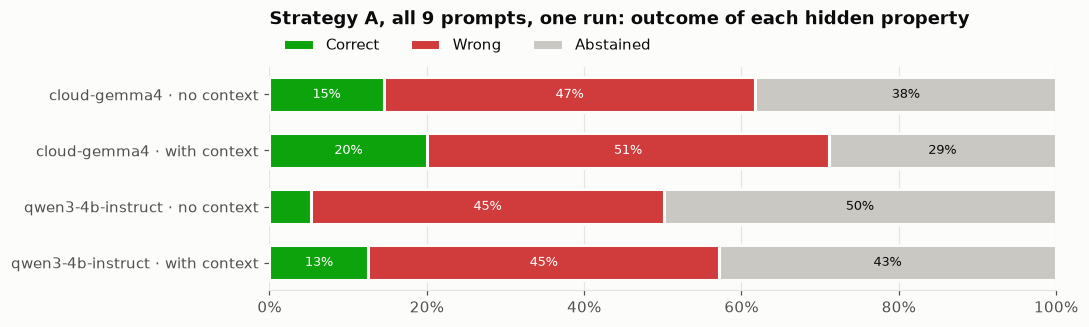

,model,context,properties,correct,wrong,abstained,precision,recall,f1
0,cloud-gemma4,False,882.0,128.0,417.0,337.0,0.235,0.145,0.179
1,cloud-gemma4,True,882.0,177.0,450.0,255.0,0.282,0.201,0.235
2,qwen3-4b-instruct,False,882.0,47.0,395.0,440.0,0.106,0.053,0.071
3,qwen3-4b-instruct,True,882.0,111.0,393.0,378.0,0.220,0.126,0.160


In [7]:
overall_a = D.standard_metrics(ss_a, ["model", "context"])
overall_a["label"] = overall_a.model + np.where(overall_a.context, " · with context", " · no context")
outcome_chart(overall_a.sort_values(["model", "context"]), "label",
              "Strategy A, all 9 prompts, one run: outcome of each hidden property")
overall_a[["model", "context", "properties", "correct", "wrong", "abstained", "precision", "recall", "f1"]].round(3)

**Strategy A works end to end, and gemma4 is ahead of qwen3-4B.** All 648 runs came back in the CSV format. Over all prompts, the standard F1 is **0.18 without context and 0.24 with it**, against 0.07 / 0.16 for qwen3-4B on its first run. Graph context helps again, from recall 0.15 to 0.20, mostly by cutting abstentions (38% to 29%), while the error rate stays about the same. The prompts differ by only a few points (F1 0.16–0.23 without context), which is within the noise of a single run over 98 properties per prompt. **The main problem is wrong answers, not abstentions:** about half of all hidden properties get a confident wrong value, so precision stays under 0.35. That is the gap Strategy B should close.

*Scoring change in this notebook:* the standard scoring now reads numbers given as text with a unit ("3600m", "662 ft", "UTC+5:30") and converts metres to feet for `altitude` and runway lengths and widths, which the graph stores in feet. Before, such answers were compared as strings and counted wrong. This raised gemma4's F1 without context from 0.11 to 0.18, and changes qwen3-4B very little (0.068 to 0.071), because qwen gives bare numbers. The published scoring is unchanged.

### 2.3 Next to the published models (published scoring, best prompt per model and condition)

Same rule as Table 3 of the paper. The proprietary models' values are the published *voted* answers (5 runs);
gemma4 and qwen3-4b have one run, which usually lowers the score.

In [8]:
pm = D.published_metrics(sp_all, ["source", "model", "context", "prompt"])
best = (pm.sort_values(["f1", "compared"], ascending=False).groupby(["model", "context"]).head(1)
          .sort_values(["context", "f1"], ascending=[True, False]))
best[["source", "model", "context", "prompt", "compared", "accuracy", "f1"]].round(3).reset_index(drop=True)

,source,model,context,prompt,compared,accuracy,f1
0,published,Claude Sonnet 4.5,False,few5,114.0,0.614,0.761
1,published,GPT-5,False,3cot,59.0,0.508,0.674
2,published,Gemini 2.5 Flash,False,few1,98.0,0.439,0.610
3,published,GPT-5 Mini,False,5cot,49.0,0.429,0.600
4,published,Gemini 2.5 Pro,False,few3,100.0,0.410,0.582
5,published,Claude Haiku 4.5,False,3cot,29.0,0.379,0.550
6,ollama,qwen3-4b-instruct,False,few1,86.0,0.314,0.478
7,ollama,cloud-gemma4,False,3cot,76.0,0.197,0.330
8,published,Claude Sonnet 4.5,True,1cot,3.0,0.667,0.800
9,published,Gemini 2.5 Pro,True,5cot,43.0,0.488,0.656


**Under the paper's scoring, gemma4 ranks below qwen3-4B (F1 0.33 vs 0.48 without context), the reverse of the standard scoring.** The published F1 counts every answered property that has a ground truth, including properties nobody asked for and values copied from the input. qwen3-4B echoes much more of the input (86 compared properties against 76 for gemma4, and 137 against 64 with context), and the echoed values are correct by construction. This is the same artefact seen in `dolap2026_ollama.ipynb`. The published voted answers of the proprietary models also come from 5 votes, against one run here. Read this table as a sanity check that the pipeline produces the paper's metric, not as a ranking.

## 3. Strategy B: plan → search → synthesize, one run

In [9]:
runs_b = D.load_runs_b(RESULTS_B)
log_b = [json.loads(l) for l in (RESULTS_B / "runs.jsonl").read_text().splitlines()]
print(runs_b.groupby(["variant", "status"]).size().unstack(fill_value=0))
# Search usage from runs.jsonl (every query of every run, whichever session ran it).
queries = [q for r in log_b for q in r["queries"]]
search_stats = pd.Series({"queries": len(queries), "answered from cache": sum(q["cached"] for q in queries),
                          "sent to Tavily": sum(not q["cached"] for q in queries),
                          "credits spent": sum(q["credits"] for q in queries),
                          "failed": sum(bool(q.get("error")) for q in queries)})
search_stats.to_frame("Strategy B search")

status           ok
variant            
search_evidence  36
search_memory    36


,Strategy B search
queries,88.0
answered from cache,45.0
sent to Tavily,43.0
credits spent,43.0
failed,0.0


### 3.1 What the agent searched

One row per (task, variant): how many queries the plan wrote, how many results came back, how many were dropped by
the blocklist (dataset sources), and whether the search came from the cache (the second variant reuses the first
one's plan and searches).

In [10]:
qrows = []
for r in log_b:
    qrows.append({"task_id": r["task_id"], "variant": r["variant"], "status": r["status"],
                  "queries": len(r["queries"]), "from_cache": sum(q["cached"] for q in r["queries"]),
                  "credits": sum(q["credits"] for q in r["queries"]),
                  "results": len(r["results"]), "blocked": sum(1 for x in r["results"] if x.get("blocked")),
                  "evidence_passed": len(r["evidence_passed"])})
q = pd.DataFrame(qrows)
print(q.groupby("variant")[["queries", "from_cache", "credits", "results", "blocked", "evidence_passed"]].sum())
print("queries per task (first variant):", q[q.variant == "search_evidence"].queries.value_counts().sort_index().to_dict())
blocked_domains = pd.Series([x["url"].split("/")[2] for r in log_b for x in r["results"] if x.get("blocked")]).value_counts()
print("blocked hosts:", blocked_domains.to_dict())

                 queries  from_cache  credits  results  blocked  evidence_passed
variant                                                                         
search_evidence       44           2     42.0      213        0              207
search_memory         44          43      1.0      213        0              207
queries per task (first variant): {1: 28, 2: 8}
blocked hosts: {}


### 3.2 Standard metrics, Strategy B vs Strategy A (no graph context)

Strategy B has no graph context, so the fair comparison is Strategy A **without context**: the `zero` prompt
(closest to B's prompts), the mean over the 9 prompts, and the best prompt chosen after the fact (optimistic).

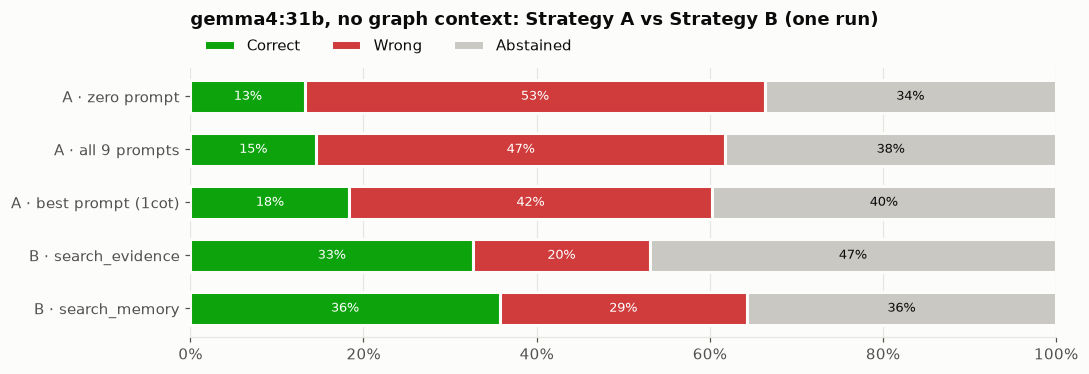

,configuration,properties,correct,wrong,abstained,precision,recall,f1
0,A · zero prompt,98.0,13.0,52.0,33.0,0.200,0.133,0.160
1,A · all 9 prompts,882.0,128.0,417.0,337.0,0.235,0.145,0.179
2,A · best prompt (1cot),98.0,18.0,41.0,39.0,0.305,0.184,0.229
3,B · search_evidence,98.0,32.0,20.0,46.0,0.615,0.327,0.427
4,B · search_memory,98.0,35.0,28.0,35.0,0.556,0.357,0.435


In [11]:
votes_b = D.voted_from_runs(runs_b, tasks).assign(context=False)
ss_b = D.score_standard(votes_b, tasks, node_values)
a_noctx = ss_a[(ss_a.model == MODEL) & ~ss_a.context]
best_prompt = D.standard_metrics(a_noctx, ["prompt"]).sort_values("f1", ascending=False).prompt.iloc[0]
rows = [("A · zero prompt", a_noctx[a_noctx.prompt == "zero"]),
        ("A · all 9 prompts", a_noctx),
        (f"A · best prompt ({best_prompt})", a_noctx[a_noctx.prompt == best_prompt])]
rows += [(f"B · {v}", ss_b[ss_b.variant == v]) for v in ["search_evidence", "search_memory"]]
cmp = pd.concat([D.standard_metrics(df.assign(_k=label), ["_k"]) for label, df in rows], ignore_index=True)
cmp = cmp.rename(columns={"_k": "configuration"})
outcome_chart(cmp, "configuration", "gemma4:31b, no graph context: Strategy A vs Strategy B (one run)")
cmp[["configuration", "properties", "correct", "wrong", "abstained", "precision", "recall", "f1"]].round(3)

**Search roughly doubles F1 at equal settings, and it does so mostly by cutting wrong answers.**

| no graph context | precision | recall | F1 |
|---|---|---|---|
| A, `zero` prompt | 0.20 | 0.13 | 0.16 |
| A, best of 9 prompts (picked after the fact) | 0.31 | 0.18 | 0.23 |
| B, `search_evidence` | **0.62** | 0.33 | 0.43 |
| B, `search_memory` | 0.56 | **0.36** | 0.44 |

Precision triples because Strategy B must cite a source for every value; without evidence the value becomes null. Wrong answers drop from 52 of 98 to 20, and abstentions go up instead. Recall still more than doubles. Letting the model add its own knowledge (`search_memory`) gains 3 correct values and adds 8 wrong ones. That is the same trade-off as Strategy A, so `search_evidence` is the cleaner variant for the paper. **This supports the premise, on one model and one run.** It needs the 5-run vote and the other model sizes before it can be a result.

### 3.3 By difficulty quadrant and by property

In [12]:
quad = pd.concat([
    D.standard_metrics(a_noctx[a_noctx.prompt == "zero"].assign(cfg="A zero"), ["cfg", "difficulty_prop"]),
    D.standard_metrics(ss_b.assign(cfg="B " + ss_b.variant), ["cfg", "difficulty_prop"]),
])
print("Recall by quadrant (H-G difficulty):")
display(quad.pivot(index="difficulty_prop", columns="cfg", values="recall").reindex(D.QUADRANTS).round(2))
prop = pd.concat([
    D.standard_metrics(a_noctx[a_noctx.prompt == "zero"].assign(cfg="A zero"), ["cfg", "property"]),
    D.standard_metrics(ss_b.assign(cfg="B " + ss_b.variant), ["cfg", "property"]),
])
pt = prop.pivot(index="property", columns="cfg", values="recall")
pt.insert(0, "n", prop.groupby("property").properties.first())
print("Recall by hidden property:")
pt.sort_values("n", ascending=False).round(2)

Recall by quadrant (H-G difficulty):


cfg,A zero,B search_evidence,B search_memory
difficulty_prop,,,
easyeasy,0.12,0.46,0.46
easyhard,0.00,0.46,0.46
hardeasy,0.28,0.32,0.40
hardhard,0.13,0.04,0.09


Recall by hidden property:


cfg,n,A zero,B search_evidence,B search_memory
property,,,,
iata,15.0,0.13,0.33,0.33
runwaysLength,12.0,0.17,0.08,0.33
runways,12.0,0.42,0.08,0.08
runwaysWidth,7.0,0.14,0.29,0.29
altitude,6.0,0.00,0.83,0.83
timezone,6.0,0.00,0.17,0.17
name,6.0,0.17,0.50,0.50
source,5.0,0.00,0.40,0.40
latitude,5.0,0.20,0.60,0.60


**Search only helps when the given properties identify the airport.** When the input names it (an IATA code, a name, a city), search finds the page and reads the values. Recall is 0.46 in the easy-easy and easy-hard quadrants, against 0.00–0.12 for Strategy A. In **hard-hard** tasks the input is only runway numbers (e.g. `runwaysWidth=60`, or `runways=1`). The agent then writes queries such as *"airport with runway width 60.0 iata code"*, which cannot find a single airport, and it correctly abstains (recall 0.04–0.09). Strategy A gets 0.13 there, mostly by guessing common values. This is a property of the task design, not of the agent: no search can identify an airport from "1 runway".

By property, search gains the most on **altitude (0.00 to 0.83)**, coordinates, IATA, name and tz_database_timezone: facts that airport pages state directly. It does worst on three:
- **`runways` (0.42 to 0.08).** Strategy A guesses "1" or "2" and is often right, while the agent abstains without a citation. Where it does answer, the graph can disagree with the web: KEUG has `runways = 3` in the graph, but its pages list 2 active runways.
- **`runwaysLength`.** The graph stores the *mean* length over all runways (e.g. 6412.3 ft for KEUG), a number no web page states.
- **`distCity`, `dst` and `source`.** These come from the dataset itself, not from the world.

These properties set a ceiling for any search strategy and should be reported separately in the paper. **The blocklist worked:** Tavily's `exclude_domains` removed the dataset sources before they reached the agent, so the local filter had nothing left to drop (0 blocked results).

### 3.4 Examples

For a few tasks: the input the agent saw, its queries, the values it returned with their sources, and the truth.

In [13]:
truth = gt.assign(prop=gt.prop_key.str.split(".").str[1]).set_index(["task_id", "prop"]).value
info = tasks.set_index("task_id")
def show(task_id, variant="search_evidence"):
    r = next(x for x in log_b if x["task_id"] == task_id and x["variant"] == variant)
    print(f"== {task_id} {info.loc[task_id, 'node_id']} ({info.loc[task_id, 'difficulty_prop']}) · {variant} · {r['status']}")
    print("input:", ", ".join(f"{g['property_name']}={g['value']}" for g in json.loads(info.loc[task_id, "G"])))
    for qq in r["queries"]:
        print(f"  query: {qq['query']!r} → {qq['n_results']} results{' (cache)' if qq['cached'] else ''}")
    for k, v in r["predictions"].items():
        p = k.split(".", 1)[1]
        src = r["evidence_urls"].get(k) or []
        print(f"  {p:<16} predicted={v!r:<40} truth={truth.get((task_id, p))}  {src[:1]}")
    print()

for t in ss_b[ss_b.variant == "search_evidence"].groupby("task_id").outcome.apply(lambda s: (s == "correct").mean()) \
            .sort_values(ascending=False).index[[0, 1, -1]]:
    show(t)

== 482e12650f248568 KEUG (easyhard) · search_evidence · ok
input: iata=EUG, runwaysLength=6412.333333333333, runways=3.0
  query: 'Airport EUG name timezone altitude' → 5 results
  timezone         predicted='UTC -7 (UTC -8 during Standard Time)'   truth=-8  ['http://www.airnav.com/airport/KEUG']
  name             predicted='Mahlon Sweet Field'                     truth="Mahlon Sweet Field"  ['http://www.airnav.com/airport/KEUG']
  altitude         predicted='373.7 ft'                               truth=374.0  ['http://www.airnav.com/airport/KEUG']

== d441c9434bf90033 HESN (easyhard) · search_evidence · ok
input: iata=ASW, runwaysLength=11161.0, runways=1.0
  query: 'Airport ASW country longitude altitude' → 5 results
  country          predicted='Egypt'                                  truth="Egypt"  ['https://en.wikipedia.org/wiki/Aswan_International_Airport']
  longitude        predicted='32.81972'                               truth=32.8199996948  ['https://en.wikipedia.org/wiki

The three examples are the two best tasks and the worst one. For **KEUG** and **HESN**, one query on the IATA code returns airnav.com or Wikipedia, and the agent reads the name, altitude and coordinates correctly. For KEUG the timezone answer "UTC -7 (UTC -8 during Standard Time)" is scored wrong (truth -8): the scorer takes the first number, and the graph stores standard time. For **ZUBJ** the input is `dst=N, altitude=4751`. The query *"airport with altitude 4751.0 feet"* returns one irrelevant page, and the agent abstains on everything instead of guessing. That is the intended behaviour of `search_evidence`.

## 4. Cost and time

In [14]:
cost = pd.DataFrame([
    {"strategy": "A", "runs": int((runs_a.model == MODEL).sum()),
     "tokens_in": runs_a.loc[runs_a.model == MODEL, "tokens_in"].sum(), "tokens_out": runs_a.loc[runs_a.model == MODEL, "tokens_out"].sum(),
     "LLM s per run": runs_a.loc[runs_a.model == MODEL, "latency_s"].mean(), "search credits": 0.0,
     "energy Wh (EcoLogits)": 1000 * runs_a.loc[runs_a.model == MODEL, "energy_kwh"].sum()},
    {"strategy": "B", "runs": len(runs_b), "tokens_in": runs_b.tokens_in.sum(), "tokens_out": runs_b.tokens_out.sum(),
     "LLM s per run": runs_b.latency_s.mean(), "search credits": search_stats["credits spent"],
     "energy Wh (EcoLogits)": 1000 * runs_b.energy_kwh.sum()},
])
cost["tokens per run"] = (cost.tokens_in + cost.tokens_out) / cost.runs
cost.round(2)

,strategy,runs,tokens_in,tokens_out,LLM s per run,search credits,energy Wh (EcoLogits),tokens per run
0,A,648,273609,15993,3.01,0.0,1.67,446.92
1,B,72,175554,10721,6.92,43.0,0.89,2587.15


**The whole test cost about 45 Tavily credits and nothing on Ollama.** (43 are recorded in the run logs. A few searches from the interrupted first session were cached and reused, so the Tavily dashboard may show a little more.) Both strategies ran on the Ollama Cloud free tier. Strategy B sent 88 queries, but 45 were answered from the cache (the second variant reuses the first one's plan and searches), so only 43 reached Tavily at basic depth, for 36 tasks. That is about 1.2 credits per task. A B run uses about 2,600 tokens, against 450 for A (the evidence), and takes about 7 s of LLM time against 3 s. The EcoLogits estimate is 1.7 Wh for all of Strategy A and 0.9 Wh for Strategy B. The search API's energy is not included.

**Projection for the real run** (5 runs, `reuse_retrieval: true`, advanced search at 2 credits): searches do not grow with the number of runs, so this dataset needs about 36 × 1.2 × 2 ≈ **90 credits per model**, and 5 models × 3 datasets about **1,400 credits**, less than the earlier estimate (2,700–3,300), because gemma4 usually writes one query per task. Larger models may write more queries per task.

## 5. Discussion

1. **The code works end to end on Ollama Cloud.** 648/648 Strategy A runs and 72/72 Strategy B runs finished, with no format failures. The ground truth matches Neo4j, the blocklist held, and the search cache served half of all queries.
2. **Gemma4:31b without search** gives about half of the hidden properties a confident wrong value, like the smaller models. Context helps a little (F1 0.18 to 0.24).
3. **With one Tavily search** it reaches F1 0.43 and precision 0.62, against 0.16–0.23 and 0.20–0.31. This is the effect the paper wants to show, measured here on a single model and run.
4. **The ceiling is set by the task design.** Search cannot help when the given properties don't identify the airport (hard-hard), or when the hidden value is a dataset artefact (mean runway length, `distCity`, `source`, `dst`) rather than a fact about the world.

## 6. Changes made for this run, and limitations

**What I changed for this run:**
- `--runs N` for both CLIs, so a test can use 1 run per configuration (the configs keep 5). The Strategy A results are in the usual folder as run 1 of `cloud-gemma4`: a later 5-run session adds runs 2–5 and reuses them.
- `configs/strategy_b_dolap2026_smoke.yaml`: gemma4 only, 1 run, **basic** Tavily depth, a 150-credit cap, at most 2 concurrent calls (the free Ollama tier answers HTTP 429 *too many concurrent requests* above that), and a separate output folder so it never mixes with the advanced-search runs.
- **Search buffer:** the search cache now normalises queries (case, spaces, trailing punctuation), searches an identical query only once when several are in flight, keeps this session's searches even under `--no-search-cache`, and stops at `search_max_credits`. The LLM cache also waits on an identical request in flight, so the two variants share one plan. `--no-cache` now only skips the LLM cache; `--no-search-cache` is a separate flag. `--retry-failed` reruns failed Strategy B runs.
- Model names on Ollama Cloud: `gemma4:31b` and `deepseek-v4-pro:0813`.
- Standard scoring reads numbers with units (see 2.2).
- **No task data was changed:** the 36 tasks, the inputs and the ground truth are the published ones, and the 6 `commercial_flights` values stay unscored.

**Limits of this test:**
- **One run, no vote.** Single-run noise at temperature 0.7 is large: per-prompt F1 differences of 0.05 are not meaningful, and the A vs B gap should be confirmed with 5 runs.
- **About 98 scored properties per configuration.** The per-quadrant and per-property tables rest on 2–15 cases per cell.
- **Basic search depth.** The real run uses advanced search, which may find more.
- **Units and formats in scoring.** A first-number rule fails on answers like "UTC -7 (UTC -8 …)" or lists of runway lengths, so it can count a right answer as wrong. The graph's own definitions (mean runway length, a runway count that includes closed runways) also set an upper bound that no model can pass.